In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/Screenshot 2026-02-03 183921.png
/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/bed.csv
/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/ward.csv
/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/department.csv
/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/drug_manufacturer.csv
/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/patient.csv
/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/drug.csv
/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/drug_inventory.csv
/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_d

In [3]:


admission = pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/admission.csv')
bed = pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/bed.csv')
billing= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/billing.csv')
billing_details = pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/billing_detail.csv')
department= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/department.csv') 
diagnostic= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/diagnostic_test.csv')
disease= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/disease.csv') 
doctor= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/doctor.csv') 
drug= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/drug.csv') 
drug_inventory= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/drug_inventory.csv') 
drug_manufacturer= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/drug_manufacturer.csv') 
employee= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/employee.csv') 
insurance_provider= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/insurance_provider.csv') 
patient= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/patient.csv') 
patient_diagnostic= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/patient_diagnostic.csv') 
patient_insurance= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/patient_insurance.csv') 
prescription= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/prescription.csv')
staff_assignment= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/staff_assignment.csv')
ward= pd.read_csv('/kaggle/input/hospital-hmis-dataset-for-healthcare-analytics/hospital_synthetic_shalaka/hospital_data/ward.csv')



In [4]:
# =========================
# Check Missing Values 
# =========================
tables = {
    "admission": admission,
    "bed": bed,
    "billing": billing,
    "billing_details": billing_details,
    "department": department,
    "diagnostic": diagnostic,
    "disease": disease,
    "doctor": doctor,
    "drug": drug,
    "drug_inventory": drug_inventory,
    "employee": employee,
    "patient": patient,
    "ward": ward
}

for name, df in tables.items():
    print(f"\n{name.upper()} TABLE")
    print(df.isnull().sum())



ADMISSION TABLE
admission_id        0
admission_date      0
discharge_date      0
admission_type      0
admission_status    0
patient_id          0
department_id       0
ward_id             0
bed_id              0
disease_id          0
dtype: int64

BED TABLE
bed_id        0
bed_number    0
bed_status    0
ward_id       0
dtype: int64

BILLING TABLE
bill_id                     0
bill_date                   0
total_amount                0
insurance_covered_amount    0
patient_payable_amount      0
payment_status              0
payment_mode                0
admission_id                0
dtype: int64

BILLING_DETAILS TABLE
billing_detail_id        0
charge_type              0
reference_id         67402
amount                   0
bill_id                  0
dtype: int64

DEPARTMENT TABLE
department_id      0
department_name    0
department_type    0
floor_number       0
status             0
dtype: int64

DIAGNOSTIC TABLE
test_id          0
test_name        0
test_category    0
standard_cos

In [5]:
# معلومات كل الجداول 
tables = {
    "Admission": admission, "Bed": bed, "Billing": billing, 
    "Billing Details": billing_details, "Department": department, 
    "Diagnostic": diagnostic, "Disease": disease, "Doctor": doctor, 
    "Drug": drug, "Drug Inventory": drug_inventory, "Employee": employee, 
    "Patient": patient, "Ward": ward
}

for name, df in tables.items():
    print(f"--- {name} Table Info ---")
    df.info()
    print("-" * 30)

--- Admission Table Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   admission_id      45000 non-null  int64 
 1   admission_date    45000 non-null  object
 2   discharge_date    45000 non-null  object
 3   admission_type    45000 non-null  object
 4   admission_status  45000 non-null  object
 5   patient_id        45000 non-null  int64 
 6   department_id     45000 non-null  int64 
 7   ward_id           45000 non-null  int64 
 8   bed_id            45000 non-null  int64 
 9   disease_id        45000 non-null  int64 
dtypes: int64(6), object(4)
memory usage: 3.4+ MB
------------------------------
--- Bed Table Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   bed_id      415 n

In [8]:

#  Admission Table

print("=== ADMISSION TABLE ===")
print(admission.describe())
for col in ['admission_type', 'admission_status']:
    print(f"\nValue counts for {col}:")
    print(admission[col].value_counts())


#  Bed Table

print("\n=== BED TABLE ===")
print(bed.describe())
for col in ['bed_status']:
    print(f"\nValue counts for {col}:")
    print(bed[col].value_counts())


# Billing Table

print("\n=== BILLING TABLE ===")
print(billing.describe())
for col in ['payment_status', 'payment_mode']:
    print(f"\nValue counts for {col}:")
    print(billing[col].value_counts())


#  Billing Details Table

print("\n=== BILLING_DETAILS TABLE ===")
print(billing_details.describe())
for col in ['charge_type']:
    print(f"\nValue counts for {col}:")
    print(billing_details[col].value_counts())

#  Department Table

print("\n=== DEPARTMENT TABLE ===")
print(department.describe())
for col in ['department_name', 'department_type', 'status']:
    print(f"\nValue counts for {col}:")
    print(department[col].value_counts())


#  Diagnostic Table

print("\n=== DIAGNOSTIC TABLE ===")
print(diagnostic.describe())
for col in ['test_name', 'test_category']:
    print(f"\nValue counts for {col}:")
    print(diagnostic[col].value_counts())


#  Disease Table

print("\n=== DISEASE TABLE ===")
print(disease.describe())
for col in ['disease_name', 'disease_category']:
    print(f"\nValue counts for {col}:")
    print(disease[col].value_counts())


#  Doctor Table

print("\n=== DOCTOR TABLE ===")
print(doctor.describe())
for col in ['specialization', 'qualification']:
    print(f"\nValue counts for {col}:")
    print(doctor[col].value_counts())


#  Drug Table

print("\n=== DRUG TABLE ===")
print(drug.describe())
for col in ['drug_name', 'brand_name', 'drug_category']:
    print(f"\nValue counts for {col}:")
    print(drug[col].value_counts())


#  Drug Inventory Table

print("\n=== DRUG_INVENTORY TABLE ===")
print(drug_inventory.describe())
for col in ['inventory_status']:
    print(f"\nValue counts for {col}:")
    print(drug_inventory[col].value_counts())

#  Employee Table

print("\n=== EMPLOYEE TABLE ===")
print(employee.describe())
for col in ['gender', 'role', 'employment_type']:
    print(f"\nValue counts for {col}:")
    print(employee[col].value_counts())


#  Patient Table

print("\n=== PATIENT TABLE ===")
print(patient.describe())
for col in ['gender', 'blood_group', 'city']:
    print(f"\nValue counts for {col}:")
    print(patient[col].value_counts())

#  Ward Table

print("\n=== WARD TABLE ===")
print(ward.describe())
for col in ['ward_name', 'ward_type']:
    print(f"\nValue counts for {col}:")
    print(ward[col].value_counts())


=== ADMISSION TABLE ===
       admission_id    patient_id  department_id      ward_id       bed_id  \
count  45000.000000  45000.000000   45000.000000  45000.00000  45000.00000   
mean   22500.500000  14912.959911       3.159044     13.52620    194.59480   
std    12990.525394   8659.657220       1.564617      7.34845    113.66573   
min        1.000000      1.000000       1.000000      1.00000      3.00000   
25%    11250.750000   7390.750000       2.000000      7.00000     98.00000   
50%    22500.500000  14878.500000       3.000000     13.00000    195.00000   
75%    33750.250000  22411.000000       4.000000     20.00000    289.00000   
max    45000.000000  30000.000000       6.000000     27.00000    414.00000   

         disease_id  
count  45000.000000  
mean      10.459844  
std        5.771013  
min        1.000000  
25%        5.000000  
50%       10.000000  
75%       15.000000  
max       20.000000  

Value counts for admission_type:
admission_type
Elective     26923
Emergen

In [9]:
# تحويل التواريخ من استرنج ل قيمه رقميه  في أهم الجداول
admission['admission_date'] = pd.to_datetime(admission['admission_date'])
admission['discharge_date'] = pd.to_datetime(admission['discharge_date'])
billing['bill_date'] = pd.to_datetime(billing['bill_date'])
patient['date_of_birth'] = pd.to_datetime(patient['date_of_birth'])

# حساب مدة إقامة كل مريض (
admission['length_of_stay'] = (admission['discharge_date'] - admission['admission_date']).dt.days
print("done")



done


In [11]:
# بشيل المسافات وبوحد الشكل في الجداول 
# Patient Table

patient['gender'] = patient['gender'].astype(str).str.strip().str.lower()
patient['blood_group'] = patient['blood_group'].astype(str).str.strip().str.upper()
patient['city'] = patient['city'].astype(str).str.strip().str.title()



# Department Table

department['department_name'] = department['department_name'].astype(str).str.strip()
department['department_type'] = department['department_type'].astype(str).str.strip().str.lower()



# Disease Table

disease['disease_name'] = disease['disease_name'].astype(str).str.strip()
disease['disease_category'] = disease['disease_category'].astype(str).str.strip().str.lower()



# Billing Table

billing['payment_status'] = billing['payment_status'].astype(str).str.strip().str.lower()
billing['payment_mode'] = billing['payment_mode'].astype(str).str.strip().str.lower()



#حاجه اضافيه من عندي     أي جداول نصوص إضافية (اختياري لكن كويس)

bed['bed_status'] = bed['bed_status'].astype(str).str.strip().str.lower()
ward['ward_name'] = ward['ward_name'].astype(str).str.strip()
ward['ward_type'] = ward['ward_type'].astype(str).str.strip().str.lower()

doctor['specialization'] = doctor['specialization'].astype(str).str.strip().str.lower()
doctor['qualification'] = doctor['qualification'].astype(str).str.strip()

drug['drug_name'] = drug['drug_name'].astype(str).str.strip()
drug['brand_name'] = drug['brand_name'].astype(str).str.strip()
drug['drug_category'] = drug['drug_category'].astype(str).str.strip().str.lower()

drug_inventory['inventory_status'] = drug_inventory['inventory_status'].astype(str).str.strip().str.lower()

print(" done ")


 done 


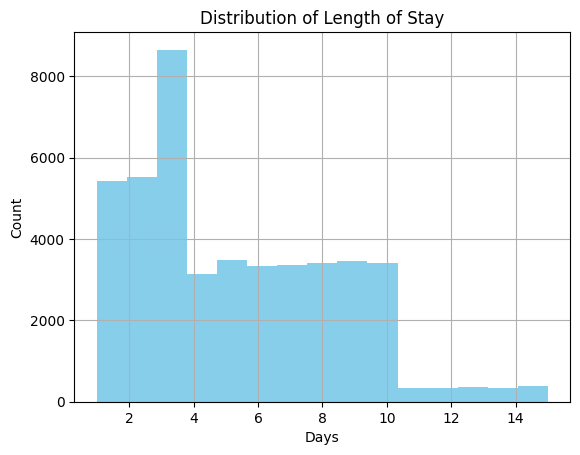

In [12]:

# -------------------- ADMISSION --------------------
# 1. توزيع length_of_stay
admission['length_of_stay'].hist(bins=15, color='skyblue')
plt.title('Distribution of Length of Stay')
plt.xlabel('Days')
plt.ylabel('Count')
plt.show()


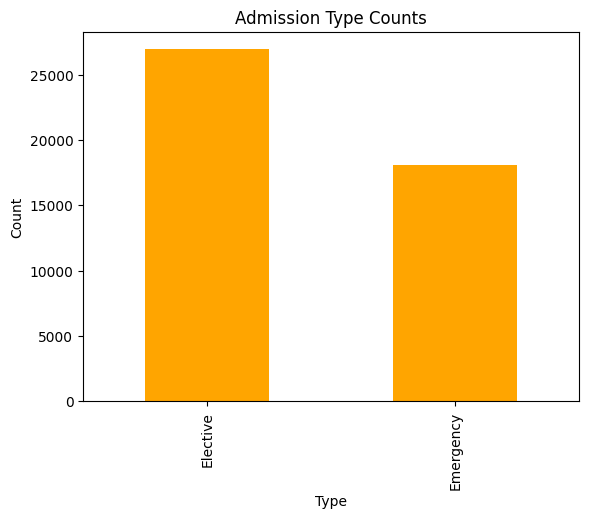

In [16]:
# 2. admission_type
admission['admission_type'].value_counts().plot(kind='bar', color='orange')
plt.title('Admission Type Counts')
plt.xlabel('Type')
plt.ylabel('Count')
plt.show()


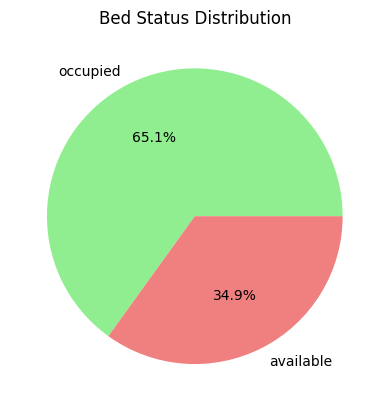

In [17]:
# Bed status
bed['bed_status'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['lightgreen', 'lightcoral'])
plt.title('Bed Status Distribution')
plt.ylabel('')
plt.show()



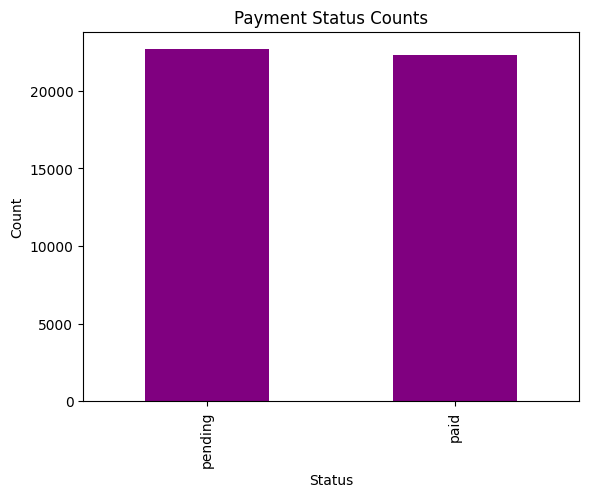

In [18]:
# -------------------- BILLING --------------------
# Payment status
billing['payment_status'].value_counts().plot(kind='bar', color='purple')
plt.title('Payment Status Counts')
plt.xlabel('Status')
plt.ylabel('Count')
plt.show()


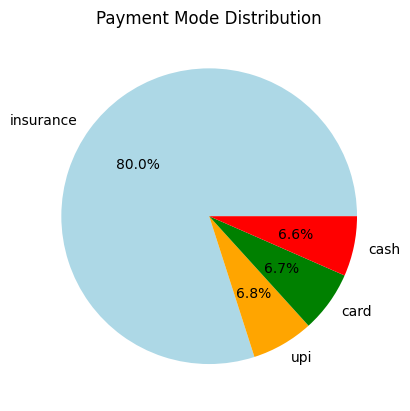

In [19]:

# Payment mode
billing['payment_mode'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['lightblue', 'orange', 'green', 'red'])
plt.title('Payment Mode Distribution')
plt.ylabel('')
plt.show()


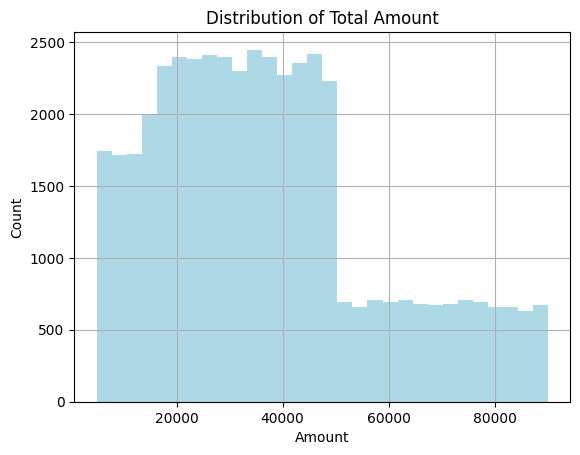

In [20]:
# Total amount histogram
billing['total_amount'].hist(bins=30, color='lightblue')
plt.title('Distribution of Total Amount')
plt.xlabel('Amount')
plt.ylabel('Count')
plt.show()


gender
male      15918
female    13478
Name: count, dtype: int64


Text(0, 0.5, 'Count')

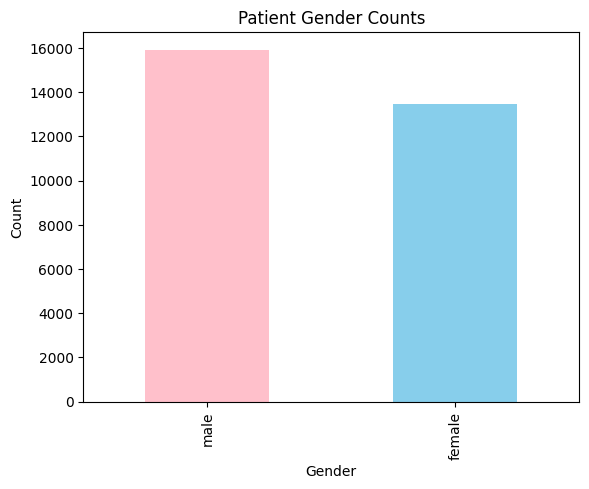

In [21]:
# -------------------- PATIENT --------------------
# كان في مجموعه اعمده القيمه فيهم other حذفتهم بقي 
patient = patient[patient['gender'] != 'other']

# التأكد
print(patient['gender'].value_counts())

# Gender
patient['gender'].value_counts().plot(kind='bar', color=['pink', 'skyblue', 'lightgreen'])
plt.title('Patient Gender Counts')
plt.xlabel('Gender')
plt.ylabel('Count')

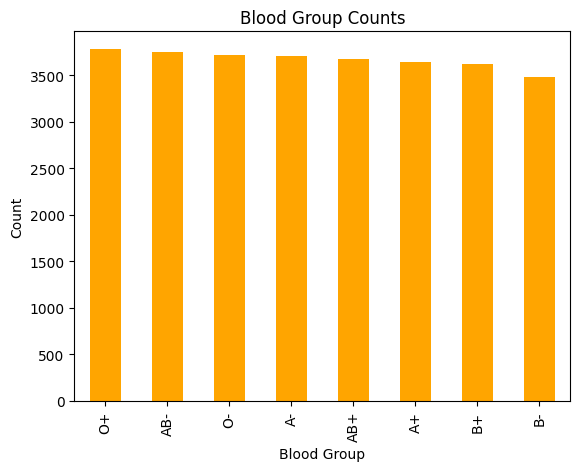

In [24]:
# Blood group
patient['blood_group'].value_counts().plot(kind='bar', color='orange')
plt.title('Blood Group Counts')
plt.xlabel('Blood Group')
plt.ylabel('Count')
plt.show()


In [25]:
# بحفظ الملفات الجديده
import os
os.makedirs("cleaned_data", exist_ok=True)

# حفظ كل جدول كـ CSV
admission.to_csv("cleaned_data/admission.csv", index=False)
bed.to_csv("cleaned_data/bed.csv", index=False)
billing.to_csv("cleaned_data/billing.csv", index=False)
billing_details.to_csv("cleaned_data/billing_details.csv", index=False)
department.to_csv("cleaned_data/department.csv", index=False)
diagnostic.to_csv("cleaned_data/diagnostic.csv", index=False)
disease.to_csv("cleaned_data/disease.csv", index=False)
doctor.to_csv("cleaned_data/doctor.csv", index=False)
drug.to_csv("cleaned_data/drug.csv", index=False)
drug_inventory.to_csv("cleaned_data/drug_inventory.csv", index=False)
employee.to_csv("cleaned_data/employee.csv", index=False)
patient.to_csv("cleaned_data/patient.csv", index=False)
ward.to_csv("cleaned_data/ward.csv", index=False)
drug_manufacturer.to_csv("cleaned_data/drug_manufacturer.csv", index=False)
insurance_provider.to_csv("cleaned_data/insurance_provider.csv", index=False)
patient_diagnostic.to_csv("cleaned_data/patient_diagnostic.csv", index=False)
patient_insurance.to_csv("cleaned_data/patient_insurance.csv", index=False)
prescription.to_csv("cleaned_data/prescription.csv", index=False)
staff_assignment.to_csv("cleaned_data/staff_assignment.csv", index=False)

print("✅ save done")





✅ save done
